# 02 · Classical baselines (main section)

### Question and falsifier, written before any result

> **Question.** Can a quantum kernel SVM learn the SAFE / UNSAFE boundary of the 3 ft x 2 ft section under biaxial bending, and how does noise distort it?
>
> **Falsifier.** The hypothesis is rejected if the boundary error of the quantum model is not lower than that of the RBF SVM at the same training size, with the same tuning effort, over five seeds, reported with 95 percent confidence intervals.

### Models (all on the same angle-scaled inputs, same training rows, same inner folds)

| model | tuning (inner stratified CV, balanced accuracy) |
|---|---|
| majority class | none, the floor every model must clear |
| logistic regression | C in {0.01, 0.1, 1, 10, 100} |
| RBF SVM | C x gamma, 5 x 5 = 25 settings (the QSVM gets the same 25) |
| MLP, two hidden layers, sigmoid output, log loss (BCE) | (16, 16) or (32, 32), ReLU or tanh |
| small MLP, 3 hidden units (16 parameters) | weight decay in {1e-4, 1e-2} |

Learning curves: training sizes 20, 40, 80, 160, 320 with seeds 0 to 4, scored once on the fixed test set.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, data_utils, metrics, models, plots

SECTION = config.MAIN_SECTION
RESULTS_DIR = config.section_results_dir(SECTION, "classical")

In [3]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)
test_rows, band_mask = data_utils.test_indices(splits)
x_test, y_test = data_utils.features_and_labels(frame, test_rows, scaler)
print(f"Test set: {len(test_rows)} rows ({int(band_mask.sum())} in the boundary band)")
print("Scaler bounds:", scaler.to_dict())

Test set: 4000 rows (1000 in the boundary band)
Scaler bounds: {'lower_bounds': [1000.0, 0.0, 0.0], 'upper_bounds': [14000.0, 457.2, 304.8]}


## 1. Learning curves

In [4]:
classical_models = {
    "majority": models.classical_fit_predict("majority"),
    "logistic": models.classical_fit_predict("logistic"),
    "rbf_svm": models.classical_fit_predict("rbf_svm"),
    "mlp": models.classical_fit_predict("mlp"),
    "mlp_small": models.classical_fit_predict("mlp_small"),
}

In [5]:
classical_results = models.run_learning_curve(classical_models, frame, splits, scaler, strategy = "random",
                                              save_path = RESULTS_DIR / "learning_curves_random.csv")
print("Saved", len(classical_results), "rows")

majority                 n=20   seed=0  band_error=0.489  test_bal_acc=0.500  false_safe=0.000  (0.0 s)
logistic                 n=20   seed=0  band_error=0.459  test_bal_acc=0.901  false_safe=0.003  (0.2 s)
rbf_svm                  n=20   seed=0  band_error=0.469  test_bal_acc=0.919  false_safe=0.000  (0.6 s)
mlp                      n=20   seed=0  band_error=0.478  test_bal_acc=0.860  false_safe=0.011  (1.4 s)
mlp_small                n=20   seed=0  band_error=0.477  test_bal_acc=0.868  false_safe=0.011  (0.4 s)
majority                 n=20   seed=1  band_error=0.489  test_bal_acc=0.500  false_safe=0.000  (0.0 s)
logistic                 n=20   seed=1  band_error=0.472  test_bal_acc=0.870  false_safe=0.103  (0.2 s)
rbf_svm                  n=20   seed=1  band_error=0.473  test_bal_acc=0.844  false_safe=0.124  (0.6 s)
mlp                      n=20   seed=1  band_error=0.472  test_bal_acc=0.836  false_safe=0.155  (0.6 s)
mlp_small                n=20   seed=1  band_error=0.484  test_b

## 2. Tables (mean and 95 percent CI over the five seeds)

In [6]:
key_metrics = ["band_error", "test_f1", "test_balanced_accuracy", "test_mcc", "test_false_safe_rate", "band_false_safe_rate"]
classical_table = metrics.mean_ci_table(classical_results, key_metrics)
classical_table.to_csv(RESULTS_DIR / "summary_random.csv")
classical_table

band_error          test_f1 test_balanced_accuracy  \
model     train_size                                                            
logistic  20          0.464 +/- 0.019  0.886 +/- 0.059        0.912 +/- 0.042   
          40          0.432 +/- 0.042  0.938 +/- 0.027        0.951 +/- 0.023   
          80          0.404 +/- 0.066  0.949 +/- 0.023        0.958 +/- 0.020   
          160         0.411 +/- 0.052  0.952 +/- 0.016        0.965 +/- 0.010   
          320         0.405 +/- 0.075  0.958 +/- 0.010        0.971 +/- 0.005   
majority  20          0.489 +/- 0.000  0.000 +/- 0.000        0.500 +/- 0.000   
          40          0.489 +/- 0.000  0.000 +/- 0.000        0.500 +/- 0.000   
          80          0.489 +/- 0.000  0.000 +/- 0.000        0.500 +/- 0.000   
          160         0.489 +/- 0.000  0.000 +/- 0.000        0.500 +/- 0.000   
          320         0.489 +/- 0.000  0.000 +/- 0.000        0.500 +/- 0.000   
mlp       20          0.476 +/- 0.036  0.823 +/- 0.085        0.874 +/- 0.068   
          40          0.424 +/- 0.039  0.933 +/- 0.016        0.948 +/- 0.012   
          80          0.414 +/- 0.065  0.937 +/- 0.034        0.950 +/- 0.032   
          160         0.347 +/- 0.082  0.968 +/- 0.020        0.977 +/- 0.015   
          320         0.301 +/- 0.033  0.977 +/- 0.007        0.984 +/- 0.004   
mlp_small 20          0.484 +/- 0.020  0.819 +/- 0.056        0.870 +/- 0.049   
          40          0.433 +/- 0.017  0.920 +/- 0.012        0.938 +/- 0.016   
          80          0.405 +/- 0.036  0.955 +/- 0.015        0.964 +/- 0.015   
          160         0.375 +/- 0.054  0.965 +/- 0.013        0.976 +/- 0.008   
          320         0.285 +/- 0.064  0.981 +/- 0.011        0.987 +/- 0.008   
rbf_svm   20          0.482 +/- 0.023  0.854 +/- 0.066        0.888 +/- 0.036   
          40          0.443 +/- 0.023  0.921 +/- 0.009        0.943 +/- 0.015   
          80          0.430 +/- 0.055  0.939 +/- 0.026        0.952 +/- 0.023   
          160         0.353 +/- 0.065  0.974 +/- 0.011        0.983 +/- 0.005   
          320         0.359 +/- 0.075  0.971 +/- 0.012        0.979 +/- 0.008   

                             test_mcc test_false_safe_rate  \
model     train_size                                         
logistic  20          0.839 +/- 0.088      0.039 +/- 0.052   
          40          0.911 +/- 0.037      0.022 +/- 0.019   
          80          0.928 +/- 0.032      0.013 +/- 0.013   
          160         0.929 +/- 0.023      0.024 +/- 0.012   
          320         0.939 +/- 0.015      0.021 +/- 0.013   
majority  20          0.000 +/- 0.000      0.000 +/- 0.000   
          40          0.000 +/- 0.000      0.000 +/- 0.000   
          80          0.000 +/- 0.000      0.000 +/- 0.000   
          160         0.000 +/- 0.000      0.000 +/- 0.000   
          320         0.000 +/- 0.000      0.000 +/- 0.000   
mlp       20          0.748 +/- 0.126      0.090 +/- 0.078   
          40          0.904 +/- 0.025      0.025 +/- 0.033   
          80          0.911 +/- 0.046      0.018 +/- 0.011   
          160         0.954 +/- 0.029      0.014 +/- 0.011   
          320         0.967 +/- 0.010      0.012 +/- 0.008   
mlp_small 20          0.741 +/- 0.087      0.090 +/- 0.062   
          40          0.887 +/- 0.018      0.028 +/- 0.037   
          80          0.934 +/- 0.020      0.015 +/- 0.005   
          160         0.948 +/- 0.018      0.020 +/- 0.015   
          320         0.972 +/- 0.016      0.011 +/- 0.009   
rbf_svm   20          0.791 +/- 0.105      0.056 +/- 0.069   
          40          0.886 +/- 0.014      0.038 +/- 0.032   
          80          0.912 +/- 0.036      0.020 +/- 0.012   
          160         0.963 +/- 0.016      0.016 +/- 0.015   
          320         0.957 +/- 0.018      0.014 +/- 0.009   

                     band_false_safe_rate  
model     train_size                       
logistic  20              0.365 +/- 0.329  
          40              0.408 

In [7]:
# Precision and recall on the random test part, for completeness
metrics.mean_ci_table(classical_results, ["test_precision", "test_recall", "test_accuracy"])

test_precision      test_recall    test_accuracy
model     train_size                                                   
logistic  20          0.918 +/- 0.104  0.862 +/- 0.078  0.930 +/- 0.039
          40          0.953 +/- 0.039  0.924 +/- 0.050  0.961 +/- 0.016
          80          0.970 +/- 0.027  0.930 +/- 0.043  0.969 +/- 0.014
          160         0.949 +/- 0.025  0.954 +/- 0.016  0.969 +/- 0.010
          320         0.954 +/- 0.028  0.963 +/- 0.012  0.974 +/- 0.007
majority  20          0.000 +/- 0.000  0.000 +/- 0.000  0.685 +/- 0.000
          40          0.000 +/- 0.000  0.000 +/- 0.000  0.685 +/- 0.000
          80          0.000 +/- 0.000  0.000 +/- 0.000  0.685 +/- 0.000
          160         0.000 +/- 0.000  0.000 +/- 0.000  0.685 +/- 0.000
          320         0.000 +/- 0.000  0.000 +/- 0.000  0.685 +/- 0.000
mlp       20          0.824 +/- 0.134  0.837 +/- 0.146  0.887 +/- 0.055
          40          0.949 +/- 0.066  0.920 +/- 0.048  0.958 +/- 0.011
          80          0.959 +/- 0.022  0.918 +/- 0.067  0.962 +/- 0.019
          160         0.970 +/- 0.024  0.967 +/- 0.022  0.980 +/- 0.013
          320         0.975 +/- 0.017  0.979 +/- 0.009  0.986 +/- 0.005
mlp_small 20          0.820 +/- 0.112  0.829 +/- 0.124  0.885 +/- 0.035
          40          0.942 +/- 0.072  0.904 +/- 0.066  0.950 +/- 0.008
          80          0.966 +/- 0.010  0.943 +/- 0.031  0.972 +/- 0.009
          160         0.957 +/- 0.030  0.973 +/- 0.019  0.977 +/- 0.008
          320         0.976 +/- 0.018  0.986 +/- 0.013  0.988 +/- 0.007
rbf_svm   20          0.883 +/- 0.137  0.831 +/- 0.027  0.908 +/- 0.048
          40          0.922 +/- 0.063  0.923 +/- 0.059  0.950 +/- 0.007
          80          0.956 +/- 0.025  0.923 +/- 0.048  0.962 +/- 0.015
          160         0.967 +/- 0.030  0.983 +/- 0.014  0.984 +/- 0.007
          320         0.970 +/- 0.020  0.972 +/- 0.014  0.982 +/- 0.008

## 3. Learning curve plots

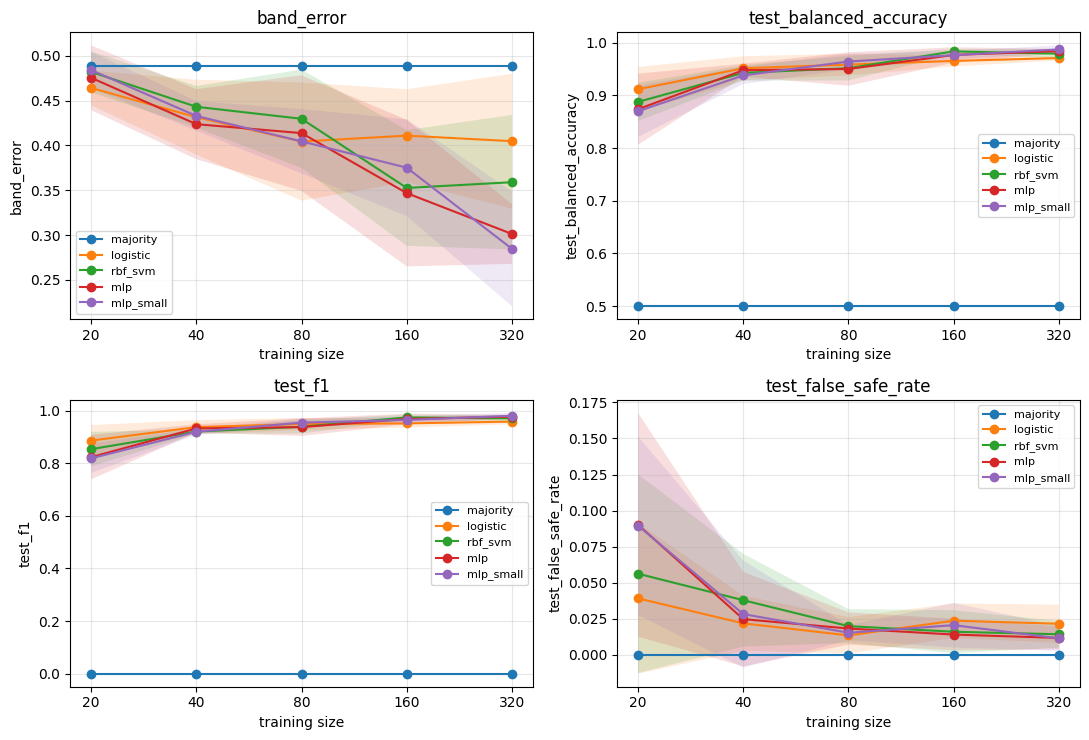

In [8]:
figure, axes = plt.subplots(2, 2, figsize = (11, 7.5))
for axis, metric_name in zip(axes.ravel(), ["band_error", "test_balanced_accuracy", "test_f1", "test_false_safe_rate"]):
    plots.learning_curve_plot(classical_results, metric_name, axis = axis, title = metric_name)
figure.tight_layout()
figure.savefig(config.figures_dir() / "classical_learning_curves.png", dpi = 200)
plt.show()

## 4. What the tuning picked

In [9]:
chosen = classical_results[classical_results["model"].isin(["rbf_svm", "mlp", "logistic"])]
chosen.pivot_table(index = ["model", "train_size"], columns = "train_seed", values = "best_params", aggfunc = "first")

train_seed                                                           0  \
model    train_size                                                      
logistic 20                                                  {'C': 10}   
         40                                                  {'C': 10}   
         80                                                   {'C': 1}   
         160                                                 {'C': 10}   
         320                                                  {'C': 1}   
mlp      20          {'activation': 'relu', 'hidden_layer_sizes': (...   
         40          {'activation': 'relu', 'hidden_layer_sizes': (...   
         80          {'activation': 'relu', 'hidden_layer_sizes': (...   
         160         {'activation': 'tanh', 'hidden_layer_sizes': (...   
         320         {'activation': 'relu', 'hidden_layer_sizes': (...   
rbf_svm  20                                  {'C': 100, 'gamma': 0.01}   
         40                                {'C': 1000, 'gamma': 0.003}   
         80                                     {'C': 1, 'gamma': 0.1}   
         160                                   {'C': 10, 'gamma': 0.1}   
         320                                {'C': 100, 'gamma': 0.001}   

train_seed                                                           1  \
model    train_size                                                      
logistic 20                                                  {'C': 10}   
         40                                                   {'C': 1}   
         80                                                   {'C': 1}   
         160                                                  {'C': 1}   
         320                                                  {'C': 1}   
mlp      20          {'activation': 'relu', 'hidden_layer_sizes': (...   
         40          {'activation': 'tanh', 'hidden_layer_sizes': (...   
         80          {'activation': 'relu', 'hidden_layer_sizes': (...   
         160         {'activation': 'tanh', 'hidden_layer_sizes': (...   
         320         {'activation': 'tanh', 'hidden_layer_sizes': (...   
rbf_svm  20                                   {'C': 10, 'gamma': 0.25}   
         40                                {'C': 1000, 'gamma': 0.001}   
         80                                    {'C': 1, 'gamma': 0.25}   
         160                                {'C': 1000, 'gamma': 0.01}   
         320                                {'C': 1000, 'gamma': 0.01}   

train_seed                                                           2  \
model    train_size                                                      
logistic 20                                                 {'C': 100}   
         40                                                   {'C': 1}   
         80                                                  {'C': 10}   
         160                                                  {'C': 1}   
         320                                                {'C': 100}   
mlp      20          {'activation': 'relu', 'hidden_layer_sizes': (...   
         40          {'activation': 'tanh', 'hidden_layer_sizes': (...   
         80          {'activation': 'relu', 'hidden_layer_sizes': (...   
         160         {'activation': 'tanh', 'hidden_layer_sizes': (...   
         320         {'activation': 'relu', 'hidden_layer_sizes': (...   
rbf_svm  20                                {'C': 1000, 'gamma': 0.003}   
         40                                 {'C': 1000, 'gamma': 0.01}   
         80                                  {'C': 100, 'gamma': 0.25}   
         160                                   {'C': 10, 'gamma': 0.1}   
         320                              {'C': 10000, 'gamma': 0.003}   

train_seed                                                           3  \
model    train_size                                                      
logistic 20                                                   {'C': 1}   
 

## 5. Predicted SAFE regions (n = 320, seed 0)

The black line is the true boundary from the capacity code. Green is predicted SAFE.

logistic  {'C': 1}  inner CV balanced accuracy 0.981
rbf_svm   {'C': 100, 'gamma': 0.001}  inner CV balanced accuracy 0.991
mlp       {'activation': 'relu', 'hidden_layer_sizes': (16, 16)}  inner CV balanced accuracy 0.981


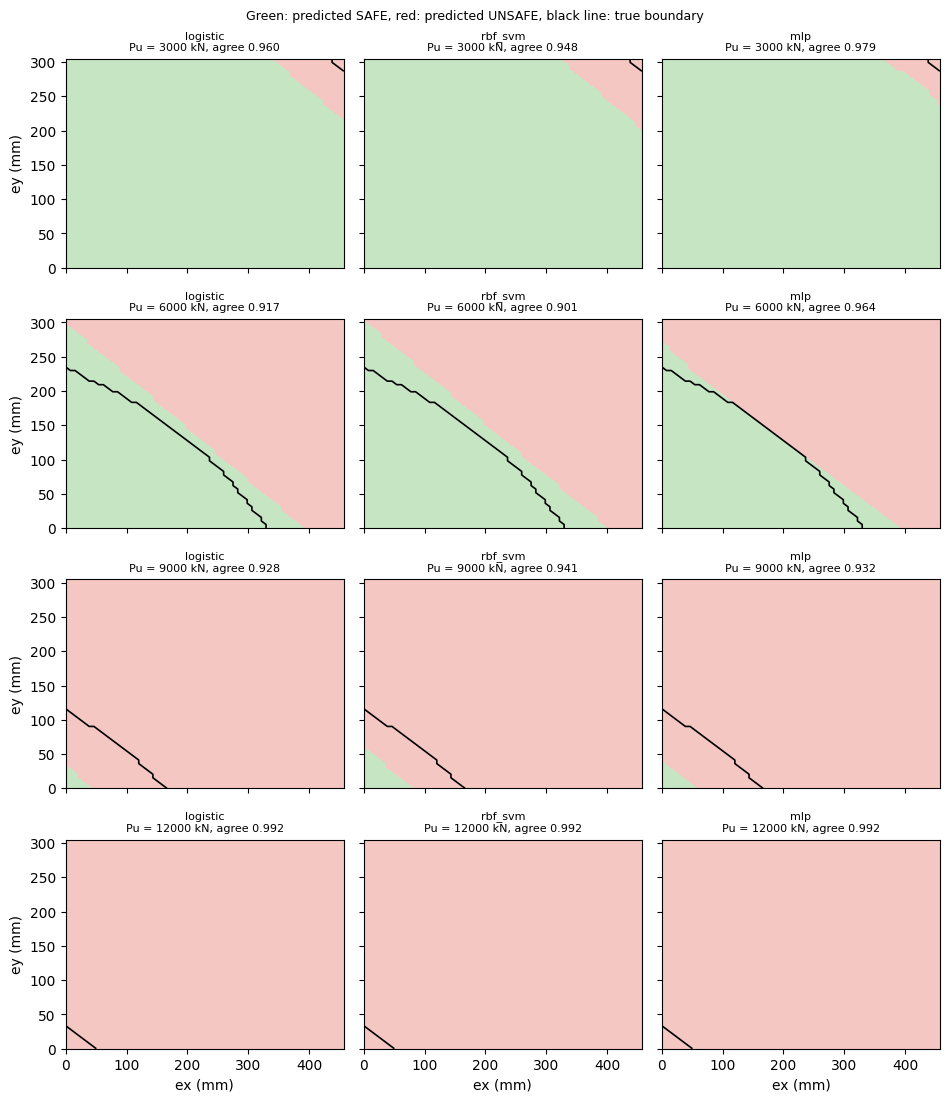

In [10]:
train_rows = data_utils.training_indices(splits, 320, 0, "random")
x_train, y_train = data_utils.features_and_labels(frame, train_rows, scaler)
fitted = {}
for name in ["logistic", "rbf_svm", "mlp"]:
    model, best_params, cv_score = models.fit_classical(name, x_train, y_train, config.run_seed(config.SEED, 0))
    fitted[name] = model
    print(f"{name:<9} {best_params}  inner CV balanced accuracy {cv_score:.3f}")

predictors = {name: model.predict for name, model in fitted.items()}
figure = plots.safe_region_figure(SECTION, scaler, predictors, pu_levels = [3000, 6000, 9000, 12000])
figure.savefig(config.figures_dir() / "classical_safe_regions_n320.png", dpi = 200)
plt.show()

**Read the majority row first.** Any model that ties it is predicting one class everywhere. Next: `03_quantum/01_qsvm_main_learning_curves.ipynb`.